# 02 Features, labels and the monthly panel

Work packages 2.4, 2.5 and 3.1 of the WBS. Starting from the clean daily prices of notebook 01, this notebook:

1. computes the seven indicators for every ETF and trading day,
2. samples them at each month-end and attaches the two labels (next month's return, and whether the ETF finishes in next month's top 3),
3. validates the panel, including a look-ahead test,
4. builds the walk-forward calendar (which rows train, tune and test each month),
5. checks every saved table against the data dictionary in `src/dictionary.py`,
6. explores the data using **pre-2020 rows only**, so nothing about the test period influences design choices.

Outputs go to `data/processed/` and `data/reports/` on Drive.

In [1]:
# Setup: run this cell first in every Colab session.
# It mounts Google Drive (where the data lives), gets the latest code from
# GitHub (where the code lives) and installs the pinned libraries.
from google.colab import drive
drive.mount("/content/drive")

import os
import sys

REPO_URL = "https://github.com/guyen5/Capstone.git"
REPO_DIR = "/content/Capstone"

# First run in a session: clone the repo. Later runs: pull the newest code.
if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull --quiet
else:
    !git clone --quiet {REPO_URL} {REPO_DIR}

%pip install --quiet -r {REPO_DIR}/requirements.txt

# Make "from src import ..." work.
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 5.4 MB/s eta 0:00:00


In [2]:
# Libraries, project modules and folders.
import importlib
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data_pull, quality, features, splits, dictionary

# Reload so edits pulled from GitHub take effect without a runtime restart.
for module in (config, data_pull, quality, features, splits, dictionary):
    importlib.reload(module)

DIRS = config.data_dirs()
pd.set_option("display.width", 160)
print("Features:", config.FEATURES)
print("Test holding months:", config.TEST_FIRST_HOLDING, "to", config.TEST_LAST_HOLDING)

Features: ['ret_1m', 'trend', 'price_bias', 'rsi14', 'macd_diff', 'boll_width', 'volume_bias']
Test holding months: 2020-01 to 2026-09


## Step 1. Load the clean daily prices

`prices_clean_v1.parquet` was built by notebook 01 from the frozen download. The freeze metadata is read so the panel records exactly which download it came from.

In [3]:
clean = quality.load_clean(DIRS["processed"])
freeze_meta = json.loads(data_pull.list_freezes(DIRS["raw"])[-1].read_text())

print(f"{len(clean):,} rows, {clean['ticker'].nunique()} tickers, "
      f"{clean['date'].min():%Y-%m-%d} to {clean['date'].max():%Y-%m-%d}")
print("Built from freeze:", freeze_meta["file"], "md5", freeze_meta["md5"])

# The clean table must still match its dictionary entry.
quality.summarize(dictionary.check_table(clean, "prices_clean_v1").rename(columns={"column": "ticker"}))

71,408 rows, 16 tickers, 2009-01-02 to 2026-09-30
Built from freeze: prices_raw_20261016.csv md5 80113beee459649ee81eda775e0eee79
PASS 14   WARN 0   FAIL 0
All checks passed.


'PASS'

## Step 2. Daily features

Seven indicators per ETF per trading day (formulas in the data dictionary). Every value at day t uses only prices and volumes up to day t.

In [4]:
daily = features.daily_features(clean)
print(f"{len(daily):,} rows")
daily[daily["ticker"] == "SPY"].dropna().tail()

71,408 rows


,date,ticker,ret_1m,trend,price_bias,rsi14,macd_diff,boll_width,volume_bias
35699,2026-09-24,SPY,0.004137,0.005106,0.005036,53.694889,0.000805,0.030161,-0.109945
35700,2026-09-25,SPY,0.009336,0.005689,0.009315,57.031282,0.001028,0.030769,-0.244487
35701,2026-09-28,SPY,-0.004665,0.005920,0.000938,51.527641,0.000631,0.030564,-0.117926
35702,2026-09-29,SPY,-0.004236,0.006428,-0.002039,50.244974,0.000211,0.030533,-0.222511
35703,2026-09-30,SPY,-0.003299,0.007372,-0.005446,48.788617,-0.000214,0.030195,0.300374


## Step 3. Monthly panel with labels

One row per universe, ETF and month-end from January 2010. `next_return` is label A (Model A), `top3_next` is label B (Model B). The newest month (September 2026) has features but no label yet.

In [5]:
panel = features.build_panel(clean, daily)

print(panel.groupby(["universe", "sample"]).size().unstack(fill_value=0))
print()
print("Month-ends:", panel["date"].nunique(),
      f"({panel['date'].min():%Y-%m} to {panel['date'].max():%Y-%m})")
print("Volume bias filled with 0 (zero-volume month-ends):",
      int(panel["volume_bias_missing"].sum()), "rows",
      panel.loc[panel["volume_bias_missing"], ["date", "ticker"]].drop_duplicates()
      .assign(date=lambda d: d["date"].dt.strftime("%Y-%m-%d")).values.tolist())
panel.head()

sample    pre_test  test  unlabeled
universe                           
ETF_A          952   648          8
ETF_B         1190   810         10

Month-ends: 201 (2010-01 to 2026-09)
Volume bias filled with 0 (zero-volume month-ends): 0 rows []


,date,universe,ticker,holding_month,sample,ret_1m,trend,price_bias,rsi14,macd_diff,boll_width,volume_bias,volume_bias_missing,next_return,next_rank,top3_next
0,2010-01-29,ETF_A,AGG,2010-02,pre_test,0.015311,0.001884,0.002213,60.561300,0.000721,0.016577,0.113872,False,0.001984,8,0
1,2010-01-29,ETF_A,DBC,2010-02,pre_test,-0.085688,-0.028383,-0.038274,27.709466,-0.010150,0.147694,0.337347,False,0.041428,1,1
2,2010-01-29,ETF_A,EEM,2010-02,pre_test,-0.073026,-0.022665,-0.046718,30.152954,-0.012620,0.161590,0.588597,False,0.017764,5,0
3,2010-01-29,ETF_A,EFA,2010-02,pre_test,-0.063132,-0.014396,-0.042772,32.054382,-0.009334,0.116450,0.223724,False,0.002667,7,0
4,2010-01-29,ETF_A,JPXN,2010-02,pre_test,-0.002551,0.035146,-0.032070,41.888634,-0.006087,0.077809,-0.630217,False,0.007662,6,0


## Step 4. Validate the panel

Structural checks, an independent recomputation of label A, and the look-ahead test: features at random month-ends are recomputed from prices cut off at that date and must match exactly.

In [6]:
panel_checks = features.validate_panel(panel, clean)
dict_checks = dictionary.check_table(panel, "monthly_panel_v1")

print(panel_checks.to_string(index=False))
print()
print(dict_checks.to_string(index=False))

all_checks = pd.concat([panel_checks.assign(column=""), dict_checks], ignore_index=True)
if (all_checks["status"] == "FAIL").any():
    raise RuntimeError("Panel check failed. Do not save or model on this panel.")

                 check status                                                                                            detail
       row count ETF_A   PASS                                                               1608 rows = 201 month-ends x 8 ETFs
       row count ETF_B   PASS                                                              2010 rows = 201 month-ends x 10 ETFs
           unique rows   PASS                                                                                  0 duplicate keys
     features complete   PASS                                                                          0 missing feature values
           rsi14 range   PASS                                                                      all values between 0 and 100
      boll_width range   PASS                                                                                all values above 0
         finite values   PASS                                                                        no 

## Step 5. Walk-forward calendar

For each of the 81 test months: the decision date, the training window (rows whose labels are known before the decision) and the 12-month validation slice. The growing window is the primary design; 36- and 60-month rolling windows are robustness checks.

In [7]:
calendars = {w: splits.walk_forward_calendar(panel, w)
             for w in ["growing", *config.ROLLING_WINDOWS]}
calendar = pd.concat(calendars.values(), ignore_index=True)

for w, cal in calendars.items():
    print(f"window {w}:")
    print(splits.check_calendar(cal, panel).to_string(index=False))
    print()
print(dictionary.check_table(calendar, "walk_forward_calendar")["status"].value_counts().to_dict())
calendars["growing"].iloc[[0, 1, -1]]

window growing:
                     check status                                                     detail
train ends before decision   PASS every training window ends at least one month-end before t
               test period   PASS                         81 test months, 2020-01 to 2026-09
  one prediction per month   PASS                                     no test month repeated
     training labels known   PASS        the newest training row of every window has a label

window 36:
                     check status                                                     detail
train ends before decision   PASS every training window ends at least one month-end before t
               test period   PASS                         81 test months, 2020-01 to 2026-09
  one prediction per month   PASS                                     no test month repeated
     training labels known   PASS        the newest training row of every window has a label

window 60:
                     check sta

,holding_month,decision_date,train_start,train_end,val_start,n_train_months,window
0,2020-01,2019-12-31,2010-01-29,2019-11-29,2018-12-31,119,growing
1,2020-02,2020-01-31,2010-01-29,2019-12-31,2019-01-31,120,growing
80,2026-09,2026-08-31,2010-01-29,2026-07-31,2025-08-29,199,growing


## Step 6. Save

Parquet for code, CSV for reading. The JSON file records where the panel came from and the settings used to build it.

In [8]:
out = DIRS["processed"]
panel.to_parquet(out / "monthly_panel_v1.parquet", index=False)
panel.to_csv(out / "monthly_panel_v1.csv", index=False)
calendar.to_parquet(out / "walk_forward_calendar_v1.parquet", index=False)
calendar.to_csv(out / "walk_forward_calendar_v1.csv", index=False)
dictionary.to_frame().to_csv(out / "data_dictionary_v1.csv", index=False)
all_checks.to_csv(DIRS["reports"] / "panel_checks_v1.csv", index=False)

meta = {
    "file": "monthly_panel_v1.parquet",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "source_freeze": freeze_meta["file"],
    "source_freeze_md5": freeze_meta["md5"],
    "rows": {u: int(n) for u, n in panel["universe"].value_counts().items()},
    "month_ends": int(panel["date"].nunique()),
    "first_date": f"{panel['date'].min():%Y-%m-%d}",
    "last_date": f"{panel['date'].max():%Y-%m-%d}",
    "features": config.FEATURES,
    "top_k": config.TOP_K,
    "test_holding_months": [config.TEST_FIRST_HOLDING, config.TEST_LAST_HOLDING],
    "volume_bias_filled_rows": int(panel["volume_bias_missing"].sum()),
}
(out / "monthly_panel_v1.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "file": "monthly_panel_v1.parquet",
  "created_utc": "2026-10-16T12:59:54+00:00",
  "source_freeze": "prices_raw_20261016.csv",
  "source_freeze_md5": "80113beee459649ee81eda775e0eee79",
  "rows": {
    "ETF_B": 2010,
    "ETF_A": 1608
  },
  "month_ends": 201,
  "first_date": "2010-01-29",
  "last_date": "2026-09-30",
  "features": [
    "ret_1m",
    "trend",
    "price_bias",
    "rsi14",
    "macd_diff",
    "boll_width",
    "volume_bias"
  ],
  "top_k": 3,
  "test_holding_months": [
    "2020-01",
    "2026-09"
  ],
  "volume_bias_filled_rows": 0
}


## Step 7. Exploration (pre-2020 rows only)

Everything below uses `sample == "pre_test"` rows of ETF_A, the primary universe. The test period (2020 onward) stays unseen until the primary specification is locked (WBS 4.3). These tables describe the data; none of them is used to choose features.

In [9]:
pre = panel[(panel["sample"] == "pre_test") & (panel["universe"] == "ETF_A")].copy()
print(f"{pre['date'].nunique()} months, {len(pre)} rows "
      f"({pre['holding_month'].min()} to {pre['holding_month'].max()})")

# 7a. Feature summary.
summary = pre[config.FEATURES].describe(percentiles=[0.05, 0.5, 0.95]).T
summary.to_csv(DIRS["reports"] / "eda_feature_summary_pre2020.csv")
summary.round(4)

119 months, 952 rows (2010-02 to 2019-12)


,count,mean,std,min,5%,50%,95%,max
ret_1m,952.0,0.0049,0.0407,-0.1972,-0.0719,0.0075,0.0640,0.1507
trend,952.0,0.0055,0.0283,-0.1049,-0.0511,0.0076,0.0472,0.0846
price_bias,952.0,0.0012,0.0144,-0.0625,-0.0227,0.0016,0.0249,0.0605
rsi14,952.0,53.9481,10.7150,20.2007,36.0727,54.2856,70.4969,83.8322
macd_diff,952.0,0.0000,0.0028,-0.0142,-0.0043,0.0000,0.0044,0.0116
boll_width,952.0,0.0556,0.0341,0.0048,0.0098,0.0506,0.1172,0.2286
volume_bias,952.0,0.2602,0.7094,-0.9825,-0.4564,0.1374,1.2962,6.2283


In [10]:
# 7b. Who finishes in the top 3? Chance level is 3/8 = 37.5% for every ETF.
top3_rate = (pre.groupby("ticker")["top3_next"].mean().sort_values(ascending=False)
             .rename("share of months in top 3"))

# 7c. Persistence: if an ETF was in the top 3 this month, how often is it
# again next month? Well above 37.5% would mean rankings are sticky, which
# favours low-turnover strategies.
pre = pre.sort_values(["ticker", "date"])
pre["top3_now"] = pre.groupby("ticker")["top3_next"].shift(1)
stay = pre.dropna(subset=["top3_now"]).groupby("top3_now")["top3_next"].mean()

print(top3_rate.round(3).to_string())
print()
print(f"P(top 3 next month | top 3 this month)     = {stay.get(1.0, np.nan):.3f}")
print(f"P(top 3 next month | not top 3 this month) = {stay.get(0.0, np.nan):.3f}")
top3_rate.to_csv(DIRS["reports"] / "eda_top3_rate_pre2020.csv")

ticker
XLK     0.521
VTI     0.445
SPY     0.403
JPXN    0.361
DBC     0.353
EEM     0.328
AGG     0.319
EFA     0.269

P(top 3 next month | top 3 this month)     = 0.404
P(top 3 next month | not top 3 this month) = 0.358


In [11]:
# 7d. Information coefficient: Spearman correlation between each feature
# and next month's return across the 8 ETFs, computed every month and then
# averaged. t-stat = mean / (std / sqrt(months)). With 8 ETFs per month,
# single-month values are very noisy; the average is what matters.
def monthly_ic(df, feature):
    return df.groupby("date").apply(
        lambda g: g[feature].corr(g["next_return"], method="spearman"),
        include_groups=False)

ic = pd.DataFrame({f: monthly_ic(pre, f) for f in config.FEATURES})
ic_table = pd.DataFrame({
    "mean IC": ic.mean(),
    "std": ic.std(),
    "t-stat": ic.mean() / (ic.std() / np.sqrt(len(ic))),
    "share of months > 0": (ic > 0).mean(),
}).round(3)
ic_table.to_csv(DIRS["reports"] / "eda_feature_ic_pre2020.csv")
ic_table

,mean IC,std,t-stat,share of months > 0
ret_1m,0.031,0.436,0.765,0.546
trend,0.091,0.419,2.380,0.555
price_bias,-0.041,0.408,-1.086,0.429
rsi14,0.009,0.437,0.225,0.471
macd_diff,-0.080,0.434,-2.005,0.420
boll_width,0.093,0.434,2.350,0.613
volume_bias,-0.080,0.409,-2.134,0.412


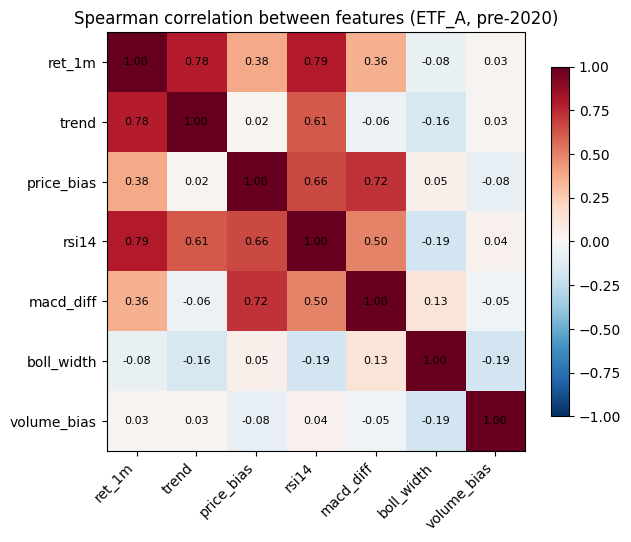

In [12]:
# 7e. How similar are the features to each other? Highly correlated pairs
# carry overlapping information (matters for the linear baselines).
corr = pre[config.FEATURES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation between features (ETF_A, pre-2020)")
plt.tight_layout()
plt.show()

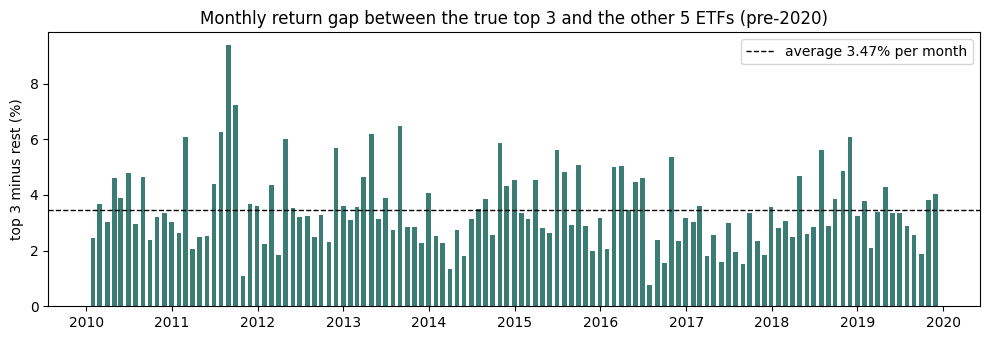

In [13]:
# 7f. How much does ranking matter? The gap between the average top-3 and
# the average bottom-5 next-month return is the most a perfect ranker could
# earn each month before fees.
gap = (pre.groupby(["date", "top3_next"])["next_return"].mean().unstack())
gap = gap[1] - gap[0]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(gap.index, gap * 100, width=20, color="#3b7d74")
ax.axhline(gap.mean() * 100, color="black", linewidth=1, linestyle="--",
           label=f"average {gap.mean():.2%} per month")
ax.set_ylabel("top 3 minus rest (%)")
ax.set_title("Monthly return gap between the true top 3 and the other 5 ETFs (pre-2020)")
ax.legend()
plt.tight_layout()
plt.show()

## Step 8. Summary for the process log

Copy this into the log. Then save the notebook to GitHub: File, Save a copy in GitHub, path `02_features_and_panel.ipynb`.

In [14]:
status = "PASS" if (all_checks["status"] == "PASS").all() else "CHECK"
print(f"Panel:           monthly_panel_v1.parquet ({status})")
print(f"Source freeze:   {freeze_meta['file']} (md5 {freeze_meta['md5']})")
print(f"Month-ends:      {panel['date'].nunique()} "
      f"({panel['date'].min():%Y-%m} to {panel['date'].max():%Y-%m})")
for u, n in panel["universe"].value_counts().sort_index().items():
    print(f"Rows {u}:      {n:,}")
print(f"Test months:     {len(calendars['growing'])} "
      f"({config.TEST_FIRST_HOLDING} to {config.TEST_LAST_HOLDING})")
print(f"Checks:          {int((all_checks['status'] == 'PASS').sum())} passed, "
      f"{int((all_checks['status'] == 'FAIL').sum())} failed")
print(f"Volume bias:     {int(panel['volume_bias_missing'].sum())} rows filled with 0")

Panel:           monthly_panel_v1.parquet (PASS)
Source freeze:   prices_raw_20261016.csv (md5 80113beee459649ee81eda775e0eee79)
Month-ends:      201 (2010-01 to 2026-09)
Rows ETF_A:      1,608
Rows ETF_B:      2,010
Test months:     81 (2020-01 to 2026-09)
Checks:          29 passed, 0 failed
Volume bias:     0 rows filled with 0
